# Session 6 – Support Vector Machines (SVM)
## Wine classification and the kernel trick

**Learning objectives**
- Explain hyperplanes, margins and support vectors.
- Train and evaluate a linear SVM.
- Understand why feature scaling matters.
- Compare linear and RBF kernels.
- Interpret classification metrics and confusion matrices.

**Datasets:** scikit-learn Wine Recognition (178 records, 13 numeric features, 3 classes) and a synthetic Two Moons dataset. We use two Wine features for 2D visualization, then all 13 features for a fuller model.

> The two-feature plot is a simplified view and does not represent all information in the Wine dataset.


## 1. SVM in simple terms

SVM searches for a decision boundary that separates classes while maximizing the **margin** (the distance to the closest training observations).

- **Hyperplane:** decision boundary.
- **Margin:** separation region around the boundary.
- **Support vectors:** observations closest to the boundary; they influence its position.
- **Kernel:** allows SVM to model more complex boundaries.

In 2D the hyperplane is a line; in higher dimensions it is a hyperplane.


## 2. Load and explore the Wine dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
print("Shape:", X.shape)
print("Classes:", list(wine.target_names))
display(X.head())


Shape: (178, 13)
Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,class_name,count
0,class_0,59
1,class_1,71
2,class_2,48


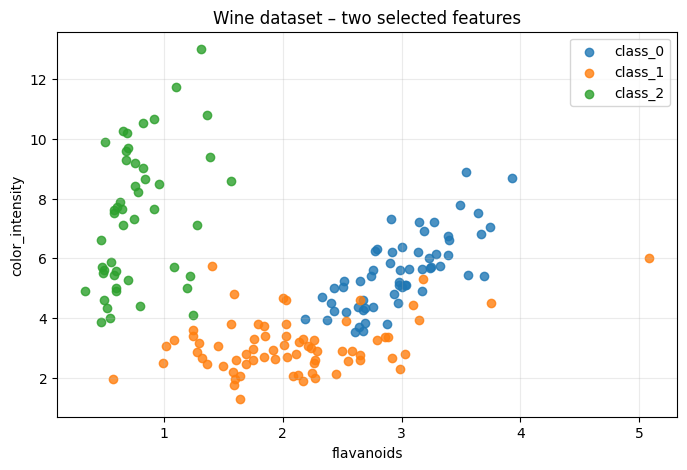

In [2]:
display(pd.DataFrame({
    "class_name": wine.target_names,
    "count": y.value_counts().sort_index().values
}))

# Two features for a 2D visualization
features = ["flavanoids", "color_intensity"]
X2 = X[features].copy()

plt.figure(figsize=(8, 5))
for i, name in enumerate(wine.target_names):
    mask = y == i
    plt.scatter(X2.loc[mask, features[0]], X2.loc[mask, features[1]],
                label=name, alpha=0.8)
plt.xlabel(features[0]); plt.ylabel(features[1])
plt.title("Wine dataset – two selected features")
plt.legend(); plt.grid(alpha=0.25); plt.show()


## 3. Split the data and scale features

SVM is sensitive to feature scales because distances and margins depend on numeric magnitude. A feature ranging from 0–1,000 can dominate one ranging from 0–1.

A `Pipeline` ensures the scaler is fitted only on training data, preventing data leakage.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X2, y, test_size=0.20, random_state=42, stratify=y
)

linear_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))
])
linear_svm.fit(X_train, y_train)
pred = linear_svm.predict(X_test)

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, target_names=wine.target_names))


Train rows: 142 | Test rows: 36
Accuracy: 0.861
              precision    recall  f1-score   support

     class_0       0.79      0.92      0.85        12
     class_1       0.85      0.79      0.81        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.86        36
   macro avg       0.88      0.87      0.87        36
weighted avg       0.87      0.86      0.86        36



## 4. Confusion matrix

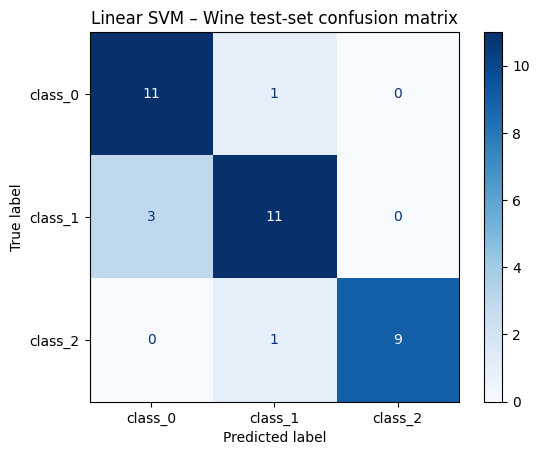

In [4]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=wine.target_names,
    cmap="Blues", values_format="d"
)
plt.title("Linear SVM – Wine test-set confusion matrix")
plt.show()


## 5. Visualize decision regions

The shaded areas show predicted classes across the two-feature plane. The points show actual observations. For this three-class task, scikit-learn's SVC uses a one-vs-one strategy internally.


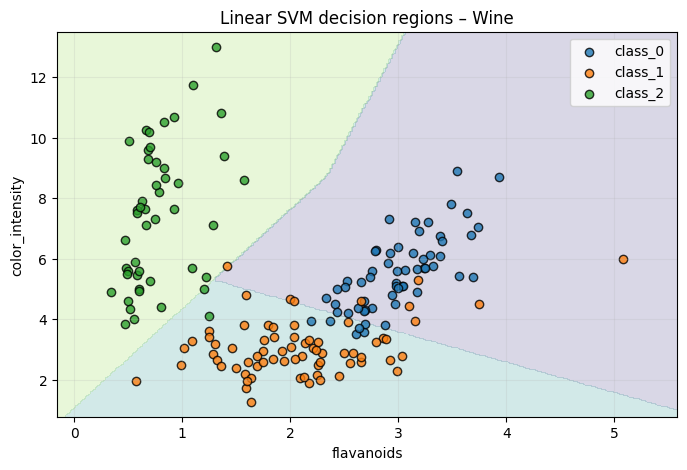

In [5]:
def plot_regions(model, X_plot, y_plot, title, feature_names):
    x0, x1 = X_plot.iloc[:, 0], X_plot.iloc[:, 1]
    xx, yy = np.meshgrid(
        np.linspace(x0.min()-0.5, x0.max()+0.5, 250),
        np.linspace(x1.min()-0.5, x1.max()+0.5, 250)
    )
    grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=feature_names)
    zz = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 5))
    plt.contourf(xx, yy, zz, alpha=0.2,
                 levels=np.arange(len(wine.target_names)+1)-0.5)
    for i, name in enumerate(wine.target_names):
        mask = y_plot == i
        plt.scatter(X_plot.loc[mask, feature_names[0]],
                    X_plot.loc[mask, feature_names[1]],
                    label=name, edgecolor="black", alpha=0.8)
    plt.xlabel(feature_names[0]); plt.ylabel(feature_names[1])
    plt.title(title); plt.legend(); plt.grid(alpha=0.2); plt.show()

plot_regions(linear_svm, X2, y, "Linear SVM decision regions – Wine", features)




```
# This is formatted as code
```

## 6. Experiment with C

`C` controls the trade-off between a wider margin and training errors.

- **Smaller C:** allows more training errors and applies stronger regularization.
- **Larger C:** penalizes training errors more strongly; this can create a more complex boundary and may overfit.

Compare training and test accuracy; do not assume the largest C is best.


In [6]:
rows = []
for c in [0.01, 0.1, 1, 10, 100]:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", C=c))
    ])
    model.fit(X_train, y_train)
    rows.append({"C": c, "train_accuracy": model.score(X_train, y_train),
                 "test_accuracy": model.score(X_test, y_test)})
display(pd.DataFrame(rows))


,C,train_accuracy,test_accuracy
0,0.01,0.816901,0.722222
1,0.10,0.922535,0.833333
2,1.00,0.915493,0.861111
3,10.00,0.922535,0.861111
4,100.00,0.936620,0.861111


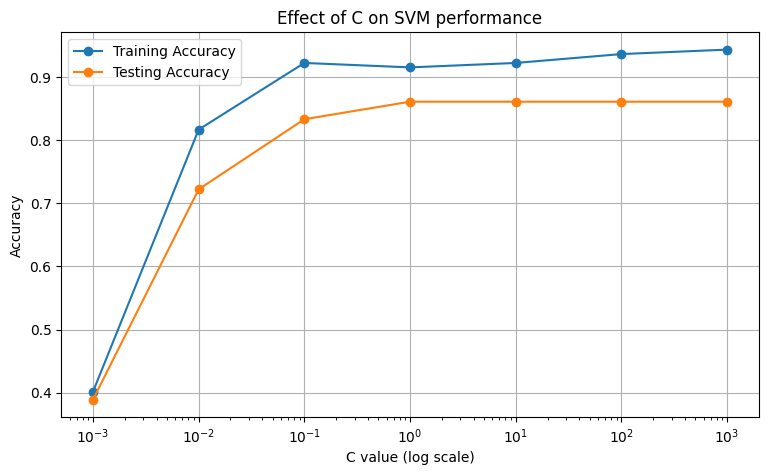

In [9]:
plt.figure(figsize=(9, 5))

plt.plot(results_df["C"],
         results_df["Training Accuracy"],
         marker="o", label="Training Accuracy")

plt.plot(results_df["C"],
         results_df["Testing Accuracy"],
         marker="o", label="Testing Accuracy")

plt.xscale("log")
plt.xlabel("C value (log scale)")
plt.ylabel("Accuracy")
plt.title("Effect of C on SVM performance")
plt.legend()
plt.grid()
plt.show()

If training accuracy increases from 85% to 99%, but testing accuracy drops from 90% to 82%, what might be happening?

Answer: The model may be overfitting. It is learning the training observations too closely and not generalizing well.

## 7. Train on all 13 Wine features

Now train on all available features.


In [7]:
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
full_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))
])
full_svm.fit(Xtr, ytr)
full_pred = full_svm.predict(Xte)

print("Accuracy:", round(accuracy_score(yte, full_pred), 3))
print("Macro precision:", round(precision_score(yte, full_pred, average="macro"), 3))
print("Macro recall:", round(recall_score(yte, full_pred, average="macro"), 3))
print("Macro F1:", round(f1_score(yte, full_pred, average="macro"), 3))
print(classification_report(yte, full_pred, target_names=wine.target_names))


Accuracy: 0.944
Macro precision: 0.951
Macro recall: 0.943
Macro F1: 0.945
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       0.93      0.93      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



## 8. Kernel trick – Two Moons dataset

A straight line cannot represent every class boundary. The RBF (Radial Basis Function) kernel lets SVM learn a curved boundary. We create a synthetic two-class dataset to make this visible.


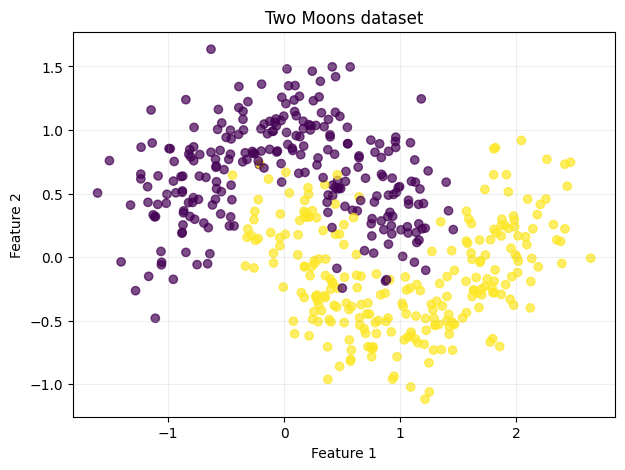

In [10]:
Xm, ym = make_moons(n_samples=500, noise=0.25, random_state=42)
Xm = pd.DataFrame(Xm, columns=["Feature 1", "Feature 2"])

Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    Xm, ym, test_size=0.20, random_state=42, stratify=ym
)

plt.figure(figsize=(7, 5))
plt.scatter(Xm.iloc[:, 0], Xm.iloc[:, 1], c=ym, alpha=0.7)
plt.title("Two Moons dataset"); plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.grid(alpha=0.2); plt.show()


In [11]:
linear_moons = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))
])
rbf_moons = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

for name, model in [("Linear SVM", linear_moons), ("RBF SVM", rbf_moons)]:
    model.fit(Xm_train, ym_train)
    print(name,
          "| train accuracy:", round(model.score(Xm_train, ym_train), 3),
          "| test accuracy:", round(model.score(Xm_test, ym_test), 3))


Linear SVM | train accuracy: 0.85 | test accuracy: 0.83
RBF SVM | train accuracy: 0.94 | test accuracy: 0.95


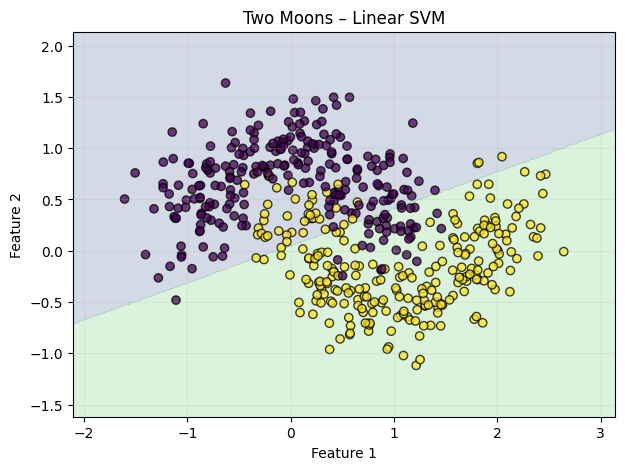

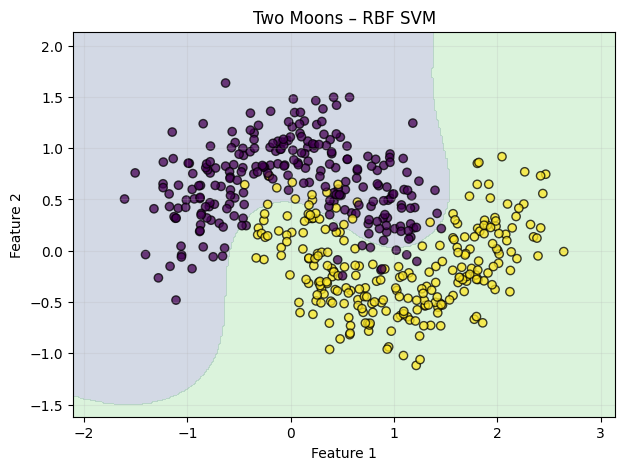

In [12]:
def plot_binary_boundary(model, Xdata, ydata, title):
    x0, x1 = Xdata.iloc[:, 0], Xdata.iloc[:, 1]
    xx, yy = np.meshgrid(
        np.linspace(x0.min()-0.5, x0.max()+0.5, 300),
        np.linspace(x1.min()-0.5, x1.max()+0.5, 300)
    )
    grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=Xdata.columns)
    zz = model.predict(grid).reshape(xx.shape)
    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, zz, alpha=0.22, levels=[-0.5, 0.5, 1.5])
    plt.scatter(x0, x1, c=ydata, edgecolor="black", alpha=0.75)
    plt.xlabel(Xdata.columns[0]); plt.ylabel(Xdata.columns[1])
    plt.title(title); plt.grid(alpha=0.2); plt.show()

plot_binary_boundary(linear_moons, Xm, ym, "Two Moons – Linear SVM")
plot_binary_boundary(rbf_moons, Xm, ym, "Two Moons – RBF SVM")


In [14]:
C_values = [0.1, 1, 10, 100]
gamma_values = [0.01, 0.1, 1, 10]

results = []

for c in C_values:
    for g in gamma_values:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", SVC(
                kernel="rbf",
                C=c,
                gamma=g
            ))
        ])

        model.fit(X_train, y_train)

        results.append({
            "C": c,
            "Gamma": g,
            "Train Accuracy": model.score(X_train, y_train),
            "Test Accuracy": model.score(X_test, y_test)
        })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Test Accuracy",
        ascending=False
    )
)

,C,Gamma,Train Accuracy,Test Accuracy
13,100.0,0.10,0.943662,0.916667
14,100.0,1.00,0.985915,0.916667
15,100.0,10.00,0.992958,0.916667
9,10.0,0.10,0.929577,0.916667
6,1.0,1.00,0.936620,0.888889
7,1.0,10.00,0.985915,0.888889
10,10.0,1.00,0.971831,0.888889
2,0.1,1.00,0.936620,0.861111
5,1.0,0.10,0.936620,0.861111
8,10.0,0.01,0.929577,0.861111


## 9. Tune C and gamma for RBF

- **C:** penalty for classification errors.
- **Gamma:** controls how far the influence of an individual training observation reaches. Higher gamma can produce a more local, intricate boundary and may overfit.

This small grid is for exploration. In a rigorous workflow, tune with cross-validation on the training data and use the test set only for final evaluation.


In [13]:
tuning = []
for c in [0.1, 1, 10, 100]:
    for gamma in [0.01, 0.1, 1, 10]:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", SVC(kernel="rbf", C=c, gamma=gamma))
        ])
        model.fit(Xm_train, ym_train)
        tuning.append({
            "C": c, "gamma": gamma,
            "train_accuracy": model.score(Xm_train, ym_train),
            "test_accuracy": model.score(Xm_test, ym_test)
        })
display(pd.DataFrame(tuning).sort_values("test_accuracy", ascending=False))


,C,gamma,train_accuracy,test_accuracy
6,1.0,1.00,0.9575,0.95
7,1.0,10.00,0.9675,0.95
13,100.0,0.10,0.9450,0.95
10,10.0,1.00,0.9650,0.95
14,100.0,1.00,0.9600,0.94
3,0.1,10.00,0.9600,0.93
2,0.1,1.00,0.9400,0.93
11,10.0,10.00,0.9750,0.92
9,10.0,0.10,0.9175,0.91
15,100.0,10.00,0.9925,0.90


## 10. Knowledge check

Discuss before looking at the suggested answers.

1. Why scale features before training an SVM?
2. What are support vectors?
3. What may happen when C becomes very large?
4. Why might a linear kernel struggle with Two Moons?
5. What does an RBF kernel help capture?
6. Why should we avoid repeatedly tuning against the test set?

### Suggested answers
1. Scaling prevents large numeric ranges from dominating distances and margins.
2. Training observations closest to the decision boundary; they influence its position.
3. Training errors are penalized strongly; the model may overfit.
4. The classes have a curved structure that a straight boundary cannot represent well.
5. Non-linear decision boundaries.
6. Repeated tuning leaks information from the test set into model selection and makes the final estimate optimistic.


## 11. Mini business challenge

A company wants to classify products into categories using measurable product attributes.

In pairs, discuss:
- Which features would you use?
- Would you start with a linear or RBF kernel? Why?
- What is the business impact of a false classification?
- Which metric would you prioritize if one type of error is more expensive?
- How would you explain the model's decision to a non-technical stakeholder?

**Key takeaway:** SVM is not simply about drawing a line. It is about finding a decision boundary that generalizes. Feature scaling, kernel choice and parameter tuning all matter.

This notebook uses educational datasets. A production model needs representative data, cross-validation, monitoring and business-specific error analysis.
